# Plug flow reactor simulation for PFOA thermal degradation

Uses a Lagrangian particle approach with an ExtensibleIdealGasConstPressureMoleReactor.
The temperature profile T(x) is imposed via the extensible reactor API, overriding the
energy equation RHS. Position x is added as an extra state variable with dx/dt = u.

The temperature profile is a sum of Gaussians fitted to the experimental data from
Weber et al., parameterized by the nominal furnace temperature.



In [92]:
import pandas as pd
import os
import re
import json
import matplotlib
import cantera as ct
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.colors as mcolors
import matplotlib.cm as cm
import matplotlib.lines as mlines

In [93]:
ct.__version__

'3.2.0'

# Temperature Functions

Temperature profile: T(x_cm, nominal_C) -> T in °C
Fitted sum of 5 Gaussians (ODR fit from gaussian_fit_temperature_profiles.py)
x in cm, nominal in °C, returns °C

In [94]:
# Parameters from the ODR fit
_BASELINE = 21.9537   # °C
_A1 = 1.942512;  _B1 = 925.0228;  _MU1 = 11.9773;  _SIGMA1 = 3.9644
_A2 = 0.630055;  _B2 = 0.0000;    _MU2 = 4.3965;   _SIGMA2 = 4.0971
_A3 = 0.343392;  _B3 = 447.7876;  _SIGMA3 = 10.7594
_MIDPOINT = 30.0  # cm

def T_profile_celsius(x_cm, nominal_C):
    """Temperature profile in °C, given position in cm and nominal temp in °C."""
    x = x_cm
    nom = nominal_C
    mid = _MIDPOINT
    return (_BASELINE
        + _A1 * max(nom - _B1, 0) * np.exp(-0.5 * ((x - (mid - _MU1)) / _SIGMA1)**2)
        + _A1 * max(nom - _B1, 0) * np.exp(-0.5 * ((x - (mid + _MU1)) / _SIGMA1)**2)
        + _A2 * max(nom - _B2, 0) * np.exp(-0.5 * ((x - (mid - _MU2)) / _SIGMA2)**2)
        + _A2 * max(nom - _B2, 0) * np.exp(-0.5 * ((x - (mid + _MU2)) / _SIGMA2)**2)
        + _A3 * max(nom - _B3, 0) * np.exp(-0.5 * ((x - mid) / _SIGMA3)**2)
    )

def T_profile_K(x_m, nominal_C):
    """Temperature in K, given position in m and nominal temp in °C."""
    x_cm = x_m * 100.0  # m -> cm
    return T_profile_celsius(x_cm, nominal_C) + 273.15

def T_average_K(nominal_C):
    """Temperature in K averaged over the reactor length, given nominal temp in °C.
    
    But weight it differently, so that it gets the RTD better.
    do 1/(mean of 1/T) instead of mean of T
    """

    return 1/(np.mean([1/T_profile_K(x, nominal_C) for x in np.linspace(0, _MIDPOINT*2, 100)]))



def dTdx_K_per_m(x_m, nominal_C):
    """Analytical dT/dx in K/m, given position in m and nominal temp in °C.

    Each Gaussian term a * coeff * exp(-0.5*((x_cm - c)/s)^2) contributes
    dT/dx_cm = a * coeff * [-(x_cm - c)/s^2] * exp(-0.5*((x_cm - c)/s)^2)

    Then dT/dx_m = dT/dx_cm * 100 (chain rule: dx_cm/dx_m = 100)
    and the °C -> K conversion doesn't affect the derivative.
    """
    x_cm = x_m * 100.0
    dTdx_cm = 0.0

    if nominal_C > _B1:
        # Outer pair
        coeff = _A1 * (nominal_C - _B1)
        z = (x_cm - (_MIDPOINT - _MU1)) / _SIGMA1
        dTdx_cm += coeff * (-z / _SIGMA1) * np.exp(-0.5 * z*z)
        z = (x_cm - (_MIDPOINT + _MU1)) / _SIGMA1
        dTdx_cm += coeff * (-z / _SIGMA1) * np.exp(-0.5 * z*z)

    if nominal_C > _B2:
        # Inner pair
        coeff = _A2 * (nominal_C - _B2)
        z = (x_cm - (_MIDPOINT - _MU2)) / _SIGMA2
        dTdx_cm += coeff * (-z / _SIGMA2) * np.exp(-0.5 * z*z)
        z = (x_cm - (_MIDPOINT + _MU2)) / _SIGMA2
        dTdx_cm += coeff * (-z / _SIGMA2) * np.exp(-0.5 * z*z)

    if nominal_C > _B3:
        # Center
        coeff = _A3 * (nominal_C - _B3)
        z = (x_cm - _MIDPOINT) / _SIGMA3
        dTdx_cm += coeff * (-z / _SIGMA3) * np.exp(-0.5 * z*z)

    # Convert cm -> m: dT/dx_m = dT/dx_cm * (dx_cm / dx_m) = dT/dx_cm * 100
    return dTdx_cm * 100.0


## Extensible Reactor: 
imposed T(x) profile with x as a state variable


In [95]:
class PFR_Reactor(ct.ExtensibleIdealGasConstPressureMoleReactor):
    """Lagrangian particle reactor with imposed temperature profile T(x).

    Extra state variable: x (position in m).
    The energy equation RHS is overwritten to impose dT/dt = dT/dx * u.
    An additional equation dx/dt = u is added.
    """

    def __init__(self, *args, nominal_temp_C, mass_flow_rate, cross_section_area,
                 **kwargs):
        super().__init__(*args, **kwargs)
        self.nominal_temp_C = nominal_temp_C
        self.mass_flow_rate = mass_flow_rate      # kg/s (constant)
        self.cross_section_area = cross_section_area  # m^2 (constant)
        self.position = 0.0  # current position in m

    def after_initialize(self, t0):
        """Called after initialize. Register extra state variable."""
        if t0 != 0:
            raise ValueError(f"Expected initialization time t0=0, got t0={t0}")
        # Add one extra equation for position x
        self.n_vars += 1
        self.i_position = self.n_vars - 1
        self.position = 0.0

    def after_get_state(self, y):
        """Append x to the state vector."""
        y[self.i_position] = self.position

    def after_update_state(self, y):
        """Read x back from the state vector."""
        self.position = y[self.i_position]

    def before_component_index(self, name):
        # Other components are handled by the method from the base Reactor class
        if name == 'position':
            return self.i_position

    def before_component_name(self, i):
        # Other components are handled by the method from the base Reactor class
        if i == self.i_position:
            return 'position'


    def after_eval(self, t, LHS, RHS):
        """Modify the RHS to impose the temperature profile and add dx/dt = u."""
        # Current position from the state
        x_m = self.position

        # Current velocity: u = mdot / (rho * A)
        velocity = self.mass_flow_rate / (self.density * self.cross_section_area)

        # Impose dT/dt = dT/dx * u
        dTdx = dTdx_K_per_m(x_m, self.nominal_temp_C)
        dTdt = dTdx * velocity

        # Temperature is state variable index 0 for IdealGasConstPressureMoleReactor
        # The governing eq is: LHS[0] * dT/dt = RHS[0]
        # So to impose our dT/dt: RHS[0] = LHS[0] * dT/dt
        RHS[0] = LHS[0] * dTdt

        # Extra equation for position: dx/dt = u
        # LHS for extra variables defaults to 1.0, so RHS = dx/dt = u
        RHS[self.i_position] = velocity


## Simulation parameters
(Weber et al. experiments)


In [96]:
# Reactor geometry
int_diam = 0.007       # m (7 mm ID)
radius = int_diam / 2
cross_area = np.pi * radius * radius  # m^2

# Flow conditions tested by Weber 
Vdot_150 = 150e-6 / 60.0  # volumetric flow rate: 150 mL/min -> m^3/s 
Vdot_50 =  50e-6 / 60.0  # volumetric flow rate: 50 mL/min -> m^3/s 


# Reactor length
length = 0.60  # m (60 cm)

# Nominal furnace temperatures to simulate (°C)
nominal_temperatures = np.arange(400, 1101, 25)

#dictionaries of initial compositions for various conditions tested by Weber et al. 

#Vdot = 150 mL/min
initial_composition_weber_150mL= {"PFOA": 4.02e-4, #402 ppm of PFOA,
                    "H2O": 7.50e-4, #750 ppm of H2O(g) 
                    "O2": 0.20975808, #Total of trace species: 4.02e-4 + 7.50e-4 = 1.152e-3, Remaining fraction for air: 1 - 1.152e-3 = 0.998848, 21% O2, 79% N2
                    "N2": 0.78908992,
                    }   

initial_composition_RMG_150mL ={"PFOA(36)": 4.02e-4, #402 ppm of PFOA,
                    "H2O(8)": 7.50e-4, #750 ppm of H2O(g) 
                    "O2(5)": 0.20975808, #Total of trace species: 4.02e-4 + 7.50e-4 = 1.152e-3, Remaining fraction for air: 1 - 1.152e-3 = 0.998848, 21% O2, 79% N2
                    "N2": 0.78908992,
                    }

#Vdot = 50 mL/min 
initial_composition_weber_50mL = {"PFOA": 4.67e-4, #467 ppm of PFOA at 50 ml/min volumetric flow
                    "H2O": 7.50e-4, #750 ppm of H2O(g) 
                    "O2": 0.20974442999999998, #Total of trace species: 4.67e-4 + 7.50e-4 = 0.001217, Remaining fraction for air: 1 - 0.001217 = 0.998783, 21% O2, 79% N2
                    "N2": 0.78903857,
                    }    

initial_composition_RMG_50mL ={"PFOA(36)": 4.67e-4, 
                    "H2O(8)": 7.50e-4, #750 ppm of H2O(g) 
                    "O2(5)": 0.20974442999999998, 
                    "N2": 0.78903857,
                    }

#dictionary for mapping RMG names to Weber names
RMG_names_to_Weber_names = {'HF(11)': 'HF', 
'C2F4(64)':'C2F4', 
'CO2(13)':'CO2', 
'C2F6(51)':'C2F6', 
'CO(12)':'CO', 
'CF4(23)': 'CF4', 
'COF2(25)':'COF2'}


## Diagnostic tools

In [97]:
def plot_rates_of_progress(gas, top_n=3, show=True, verbose=True):
    """Plot forward (blue) and reverse (red) rates of progress for all reactions."""
    # Plot forward and reverse rates
    plt.semilogy(gas.forward_rates_of_progress, 'b.', label='Forward')
    plt.semilogy(gas.reverse_rates_of_progress, 'r.', label='Reverse')

    # Label highest forward and reverse rates
    top_forward = np.argsort(gas.forward_rates_of_progress)[-top_n:]
    top_reverse = np.argsort(gas.reverse_rates_of_progress)[-top_n:]
    for idx in top_forward:
        plt.text(idx, gas.forward_rates_of_progress[idx], f'R{idx}', color='blue', fontsize=8)
        if verbose:
            print(
                f"R{idx}: {gas.reaction(idx).equation}  "
                f"Forward ROP: {gas.forward_rates_of_progress[idx]:.3e}"
            )
    for idx in top_reverse:
        plt.text(idx, gas.reverse_rates_of_progress[idx], f'R{idx}', color='red', fontsize=8)
        if verbose:
            print(
                f"R{idx}: {gas.reaction(idx).equation}  "
                f"Reverse ROP: {gas.reverse_rates_of_progress[idx]:.3e}"
            )
    max_rop = max(max(gas.forward_rates_of_progress), max(gas.reverse_rates_of_progress))
    tenth_top = sorted(list(gas.forward_rates_of_progress) + list(gas.reverse_rates_of_progress))[-10]
    plt.ylim(tenth_top/1e10, max_rop*10)
    plt.xlabel('Reaction')
    plt.ylabel('Rate of Progress')
    plt.title('Rates of Progress for All Reactions')
    plt.legend()
    if show:
        plt.show()

def find_culprit_reactions(gas, species_index=None, species_name=None):
    """Find the top reactions contributing to the net production/consumption of a species."""
    if species_index is not None:
        k = species_index
    elif species_name is not None:
        k = gas.species_index(species_name)
    else:
        raise ValueError("Either species_index or species_name must be provided")

    # Stoich coefficients for species k across all reactions
    nu = gas.product_stoich_coeffs[k, :] - gas.reactant_stoich_coeffs[k, :]
    
    # Absolute total rate
    rop = abs(gas.forward_rates_of_progress) + abs(gas.reverse_rates_of_progress)
    
    # Contribution of each reaction to species k
    contrib = nu * rop
    
    # Sort by magnitude
    top = np.argsort(np.abs(contrib))[::-1][:8]
    
    print(f"\nTop reactions affecting {gas.species_name(k)}:")
    for idx in top:
        if contrib[idx] != 0:
            print(f"  R{idx}: {gas.reaction(idx).equation}  "
                  f"(rate contribution: {contrib[idx]:.4e})")


# Run simulations

In [98]:
def color_for_temperature(value, min_temp=400, max_temp=1100):
    color_map = plt.get_cmap('plasma')
    clipped_value = np.clip(value, min_temp, max_temp)
    normalized = (clipped_value - min_temp) / (max_temp - min_temp)
    return color_map(normalized)


def get_experiment_data_150mLmin(spec): 
    """retrieve the raw data, given via an excel sheet from Weber. Inital concentrations in excel sheet: PFOA 402 ppm.  """
    init_PFOA = 402
    
    exp_temp = [400, 425, 450, 500, 550, 575, 630, 660, 690, 720, 765, 800, 835, 875, 910, 975, 1000] #experimental measurements do not include 475
    
    HF_conc = [0, 0, 3.02, 49.47, 149.8, 221.17, 290.88, 467.82, 762.73, 1433, 1671, 1756, 1868, 1888, 1910, 1922, 1931] #double checked
    COF2_conc = [0, 0, 0, 0, 0, 0, 7.28, 11.44, 15.13, 17.21, 32.82, 188.28, 333.53, 565.88, 667.69, 677.92, 680.17] #double checked
    CO2_conc = [0, 0, 1.09, 24.82, 47.31, 61.37, 142, 301, 416, 569, 612.45, 706.13, 804.46, 815, 822, 827, 838] #double checked
    CO_conc = [0, 0, 0, 6.12, 9.82, 11.27, 19.89, 62.25, 202.36, 301.08, 410, 486, 580, 610, 640, 670, 690] #double checked
    C2F6_conc = [0, 0, 0, 0, 0, 0, 8.7, 11.5, 15.3, 21.2, 98.23, 226, 268.87, 301, 322, 366, 371] #double checked
    C2F4_conc = [0, 0, 0, 0, 0, 0, 1.76, 13.36, 36.59, 60.28, 58.33, 10.36, 0, 0, 0, 0, 0] #double checked 
    CF4_conc = [0, 0, 0, 0, 0, 0, 1.2, 1.59, 2.43, 2.94, 4.69, 11.07, 26.27, 52.85, 78.85, 100, 110] #double checked
    
    conc_ratio_dict = {'HF' : np.array(HF_conc)/init_PFOA, 
    'COF2' : np.array(COF2_conc)/init_PFOA, 
    'CO2' : np.array(CO2_conc) / init_PFOA, 
    'CO' : np.array(CO_conc) / init_PFOA, 
    'C2F6' : np.array(C2F6_conc) / init_PFOA, 
    'C2F4' : np.array(C2F4_conc) / init_PFOA, 
    'CF4' : np.array(CF4_conc) / init_PFOA}
    
    return (exp_temp, conc_ratio_dict[spec])


def get_experiment_data_50mLmin(spec): #this is for a plot in the SI 
    """retrieve the raw data, given via an excel sheet from Weber. Initial concentrations in excel sheet: PFOA 467 ppm, H2O 750 ppm"""
    init_PFOA = 467 #ppm 
    
    approx_temp = [390, 410, 440, 510, 540, 570, 615, 660, 710, 765, 800, 835, 875, 910, 975, 1000] #double checked
    
    HF_conc = [0, 0, 10, 233, 280, 450, 617, 864, 1027, 1274, 1459, 1525, 1623, 1658, 1666, 1721] #double checked
    COF2_conc = [0, 0, 0, 0, 31, 132, 173, 214, 226, 409, 620, 647, 722, 711, 709, 710] #double checked
    CO2_conc = [1, 8, 31, 75, 161, 254, 276, 336, 502, 1249, 1499, 1578, 1627, 1602, 1522, 1515] #double checked
    CO_conc = [0, 5, 31, 27, 48, 211, 283, 378, 435, 502, 517, 712, 798, 830, 830, 848]
    C2F6_conc = [0, 0, 0, 4, 6, 7, 16, 62, 88, 138, 208, 313, 286, 242, 211, 126]
    C2F4_conc = [0, 0, 0, 0, 0, 0, 4, 15, 31, 73, 61, 42, 21, 16, 0, 0]
    CF4_conc = [0, 0, 0, 3, 2, 2, 2, 2, 2, 3, 48, 156, 201, 242, 248, 279]
    
    conc_ratio_dict = {'HF' : np.array(HF_conc)/init_PFOA, 
    'COF2' : np.array(COF2_conc)/init_PFOA, 
    'CO2' : np.array(CO2_conc) / init_PFOA, 
    'CO' : np.array(CO_conc) / init_PFOA, 
    'C2F6' : np.array(C2F6_conc) / init_PFOA, 
    'C2F4' : np.array(C2F4_conc) / init_PFOA, 
    'CF4' : np.array(CF4_conc) / init_PFOA}
    
    return (approx_temp, conc_ratio_dict[spec])


def get_exit_concentration_ratio(results, species_of_interest, weber=False):
    # find concentration along the reactor
    exit_concentrations = []
    nominal_temps_to_plot = []
    for nominal_T_C in nominal_temperatures:
        r = results[nominal_T_C]
        states = r['states']
        if species_of_interest in states.species_names:
            idx = states.species_index(species_of_interest)
            if weber: 
                PFOA_idx = states.species_index('PFOA')
            else:
                PFOA_idx = states.species_index('PFOA(36)')
            spec_conc = states.concentrations[:, idx]
            PFOA_conc = states.concentrations[:, PFOA_idx]
            concentration_ratio = spec_conc[-1]/PFOA_conc[0]
            exit_concentrations.append(concentration_ratio)
            nominal_temps_to_plot.append(nominal_T_C)
    return exit_concentrations, nominal_temps_to_plot


def get_experiment_data(exp_label):
        
    spec_data=pd.read_csv(f'./weber_experiment_data/{exp_label}.csv')
        
    exp_data = {}
    for header in ['model', 'experiments', 'error']:
        index_of_x = spec_data.columns.get_loc(header)
        index_of_y = index_of_x+1 

        x_values_raw = spec_data.iloc[:, index_of_x]
        x_values = [float(x) for x in x_values_raw[1:]] #removes first header of 'X' or 'Y'
    
        y_values_raw = spec_data.iloc[:, index_of_y]
        y_values = [float(x) for x in y_values_raw[1:]]
        
        exp_data[header]=(x_values, y_values)
        
        
    return exp_data

# PFR Simulation

In [99]:
#for saving simulation data 
pfr_simulation_results_at_various_setpoints_RMG = {}
pfr_simulation_results_at_various_setpoints_weber = {}

In [107]:
#full path to yaml file 
yaml_path= './RMG_present_work.yaml' #RMG mechanism presented in this work
#yaml_path = './weber_experiment_data/PFAS_O2_H2O_N2O_publish.yaml' #mechanism from Weber et al. 


############# main simulation code for PFR simulation ########################

#first, check if we are simulating the weber mechanism:
if 'weber_experiment_data' in yaml_path: 
    weber_flag = True 
    init_comp = initial_composition_weber_150mL #load the initial compositions, with Weber naming 
    #init_comp = initial_composition_weber_50mL #for Vdot = 50 mL/min  
    
else: 
    weber_flag = False 
    init_comp = initial_composition_RMG_150mL #load the initial compositions, with RMG naming 
    # init_comp = initial_composition_RMG_50mL #for Vdot = 50 mL/min  



print(f'Beginning simulation for the following yaml file: {yaml_path}')
    
gas = ct.Solution(yaml_path)
print('Successfully loaded gas.')


Vdot = Vdot_150
#Vdot = Vdot_50 #uncomment for Vdot = 50 mL/min
print(f'Inlet flow rate of PFR (Vdot) = {Vdot} mL/min')

gas.TPX = 298.15, ct.one_atm, init_comp
rho_inlet = gas.density
mass_flow_rate = rho_inlet * Vdot

for nominal_T_C in nominal_temperatures:

        
    print(f"\n{'='*60}")
    print(f"Simulating nominal temperature: {nominal_T_C} °C")
    print(f"{'='*60}")

    # Set up the gas at inlet conditions
    T_inlet_K = T_profile_K(0.0, nominal_T_C)
    gas.TPX = T_inlet_K, ct.one_atm, init_comp

    print(f"  Inlet T: {T_inlet_K:.1f} K ({T_inlet_K - 273.15:.1f} °C)")
    print(f"  Mass flow rate: {mass_flow_rate:.6e} kg/s")
    print(f"  Inlet velocity (at 298.15K): {Vdot / cross_area:.4f} m/s")
    print(f"  Inlet velocity (at T_inlet): {mass_flow_rate / (gas.density * cross_area):.4f} m/s")

    # Create the extensible reactor
    reactor = PFR_Reactor(
        gas, clone=True,
        nominal_temp_C=nominal_T_C,
        mass_flow_rate=mass_flow_rate,
        cross_section_area=cross_area,
    )

    # Create reactor network
    sim = ct.ReactorNet([reactor])    


    # preconditioner -  seems to work, to speed the solver up!
    sim.derivative_settings = {"skip-third-bodies":True, "skip-falloff":True}
    sim.preconditioner = ct.AdaptivePreconditioner()
    print('Starting to initialize simulation.')
    sim.initialize()
    print('Finished initializing simulation.')

    
    # Storage for results (adaptive number of points)
    t_values = []
    x_values = []
    T_values = []
    states = ct.SolutionArray(reactor.phase)


    # Integrate
    n = 0
    hit_solver_error = False
    while reactor.position < length:
        n += 1
        try:
            sim.step()
        except ct.CanteraError as e:
            hit_solver_error = True
            print(f"  Error occurred at step {n}: {e}")
            m = re.search(r"Components with largest weighted error estimates:\n(\d+).*\n(\d+).*\n(\d+)", str(e))
            if m:
                print(f"  Problematic components: {m.group(1)}, {m.group(2)}, {m.group(3)}")
                print(sim.component_name(int(m.group(1))))
                print(sim.component_name(int(m.group(2))))
                print(sim.component_name(int(m.group(3))))
                if len(states) > 0:
                    try: 
                        last_good_state = states[-1]
                        find_culprit_reactions(last_good_state, species_index=int(m.group(1))-1)
                        find_culprit_reactions(last_good_state, species_index=int(m.group(2))-1)
                        find_culprit_reactions(last_good_state, species_index=int(m.group(3))-1)
                        #plot_rates_of_progress(last_good_state)
                    except IndexError: 
                        pass
            break

        t_values.append(sim.time)
        x_values.append(reactor.position)
        T_values.append(reactor.phase.T)
        states.append(reactor.phase.state)

    if hit_solver_error:
        print(f"  Final position before failure: x = {reactor.position:.4f} m (target: {length:.4f} m)")
        
    else:
        time_at_end_of_reactor = sim.time
        print(f"  Reached end of reactor at step {n}, "
              f"t = {sim.time:.6f} s, x = {reactor.position:.4f} m")


    if weber_flag==False: 
        
        species_to_get_concentration_ratios_for = ['HF(11)', 'C2F4(64)', 'CO2(13)', 'C2F6(51)', 'CO(12)', 'CF4(23)', 'COF2(25)'] #with RMG naming


        exit_concentrations_for_species_at_this_setpoint = {} #for saving the exit concentrations of each species of interest
        
        for species_of_interest in species_to_get_concentration_ratios_for: 
            if species_of_interest in states.species_names:
                    idx = states.species_index(species_of_interest)
                    PFOA_idx = states.species_index('PFOA(36)')
                    spec_conc = states.concentrations[:, idx]
                    PFOA_conc = states.concentrations[:, PFOA_idx]
                    X_PFOA = states.X[:, PFOA_idx]
                    exit_concentration_ratio = spec_conc[-1]/PFOA_conc[0]
                    #save the concentration ratio for this species to the dictionary
                    exit_concentrations_for_species_at_this_setpoint[RMG_names_to_Weber_names[species_of_interest]] = exit_concentration_ratio
        
        #save the PFOA concentration along the reactor length
        exit_concentrations_for_species_at_this_setpoint['PFOA'] = X_PFOA.tolist()
        
        pfr_simulation_results_at_various_setpoints_RMG[float(nominal_T_C)] = {
            # 't': np.array(t_values),
            # 'x': np.array(x_values),
            # 'T': np.array(T_values),
            't': t_values,
            'x': x_values,
            'T': T_values, 
            **exit_concentrations_for_species_at_this_setpoint, # unpacks all species_name-exit_concentration pairs from this dict
        }


    if weber_flag==True: 

        species_to_get_concentration_ratios_for = ['HF', 'C2F4', 'CO2', 'C2F6', 'CO', 'CF4', 'COF2'] #species names in Weber model
        
        exit_concentrations_for_species_at_this_setpoint = {} #for saving the exit concentrations of each species of interest
        
        for species_of_interest in species_to_get_concentration_ratios_for: 
            if species_of_interest in states.species_names:
                    idx = states.species_index(species_of_interest)
                    PFOA_idx = states.species_index('PFOA')
                    spec_conc = states.concentrations[:, idx]
                    PFOA_conc = states.concentrations[:, PFOA_idx]
                    X_PFOA = states.X[:, PFOA_idx]
                    exit_concentration_ratio = spec_conc[-1]/PFOA_conc[0]
                    #save the concentration ratio for this species to the dictionary
                    exit_concentrations_for_species_at_this_setpoint[species_of_interest] = exit_concentration_ratio
                
        #save the PFOA concentration along the reactor length
        exit_concentrations_for_species_at_this_setpoint['PFOA'] = X_PFOA.tolist()


        pfr_simulation_results_at_various_setpoints_weber[float(nominal_T_C)] = {
            # 't': np.array(t_values),
            # 'x': np.array(x_values),
            # 'T': np.array(T_values),
            't': t_values,
            'x': x_values,
            'T': T_values, 
            **exit_concentrations_for_species_at_this_setpoint, # unpacks all species_name-exit_concentration pairs from this dict
        }



# For saving the data: open a file in write mode ('w') and dump the data

#save the pfr simulation results for the weber mechanism
if weber_flag==True: 
    filename = "./weber_mechanism_results.json"
    with open(filename, "w") as file:
        json.dump(pfr_simulation_results_at_various_setpoints_weber, file)

#save the pfr simulation results for the RMG mechanism 
if weber_flag==False: 
    filename = "./RMG_present_work_results.json"
    with open(filename, "w") as file:
        json.dump(pfr_simulation_results_at_various_setpoints_RMG, file)

Beginning simulation for the following yaml file: ./weber_experiment_data/PFAS_O2_H2O_N2O_publish.yaml
Successfully loaded gas.
Inlet flow rate of PFR (Vdot) = 2.4999999999999998e-06 mL/min

Simulating nominal temperature: 400 °C
  Inlet T: 295.1 K (22.0 °C)
  Mass flow rate: 2.963100e-06 kg/s
  Inlet velocity (at 298.15K): 0.0650 m/s
  Inlet velocity (at T_inlet): 0.0643 m/s
Starting to initialize simulation.
Finished initializing simulation.


/tmp/ipykernel_1564561/2661786236.py:23: UserWarning: NasaPoly2::validate: 
For species HOCO, discontinuity in h/RT detected at Tmid = 1000
	Value computed using low-temperature polynomial:  -17.236856747666668
	Value computed using high-temperature polynomial: -16.91235667243

  gas = ct.Solution(yaml_path)
/tmp/ipykernel_1564561/2661786236.py:52: UserWarning: NasaPoly2::validate: 
For species HOCO, discontinuity in h/RT detected at Tmid = 1000
	Value computed using low-temperature polynomial:  -17.236856747666668
	Value computed using high-temperature polynomial: -16.91235667243

  reactor = PFR_Reactor(


  Reached end of reactor at step 4293, t = 7.777279 s, x = 0.6003 m

Simulating nominal temperature: 425 °C
  Inlet T: 295.1 K (22.0 °C)
  Mass flow rate: 2.963100e-06 kg/s
  Inlet velocity (at 298.15K): 0.0650 m/s
  Inlet velocity (at T_inlet): 0.0643 m/s
Starting to initialize simulation.
Finished initializing simulation.
  Reached end of reactor at step 4206, t = 7.734277 s, x = 0.6011 m

Simulating nominal temperature: 450 °C
  Inlet T: 295.1 K (22.0 °C)
  Mass flow rate: 2.963100e-06 kg/s
  Inlet velocity (at 298.15K): 0.0650 m/s
  Inlet velocity (at T_inlet): 0.0643 m/s
Starting to initialize simulation.
Finished initializing simulation.
  Reached end of reactor at step 11181, t = 7.658480 s, x = 0.6000 m

Simulating nominal temperature: 475 °C
  Inlet T: 295.3 K (22.1 °C)
  Mass flow rate: 2.963100e-06 kg/s
  Inlet velocity (at 298.15K): 0.0650 m/s
  Inlet velocity (at T_inlet): 0.0643 m/s
Starting to initialize simulation.
Finished initializing simulation.
  Reached end of reac

# Plotting

In [108]:
plt.rcParams['axes.labelsize'] = 18
plt.rcParams['xtick.labelsize'] = 15
plt.rcParams['ytick.labelsize'] = 15
plt.rcParams['figure.autolayout'] = True
matplotlib.rcParams['font.family'] = 'serif'

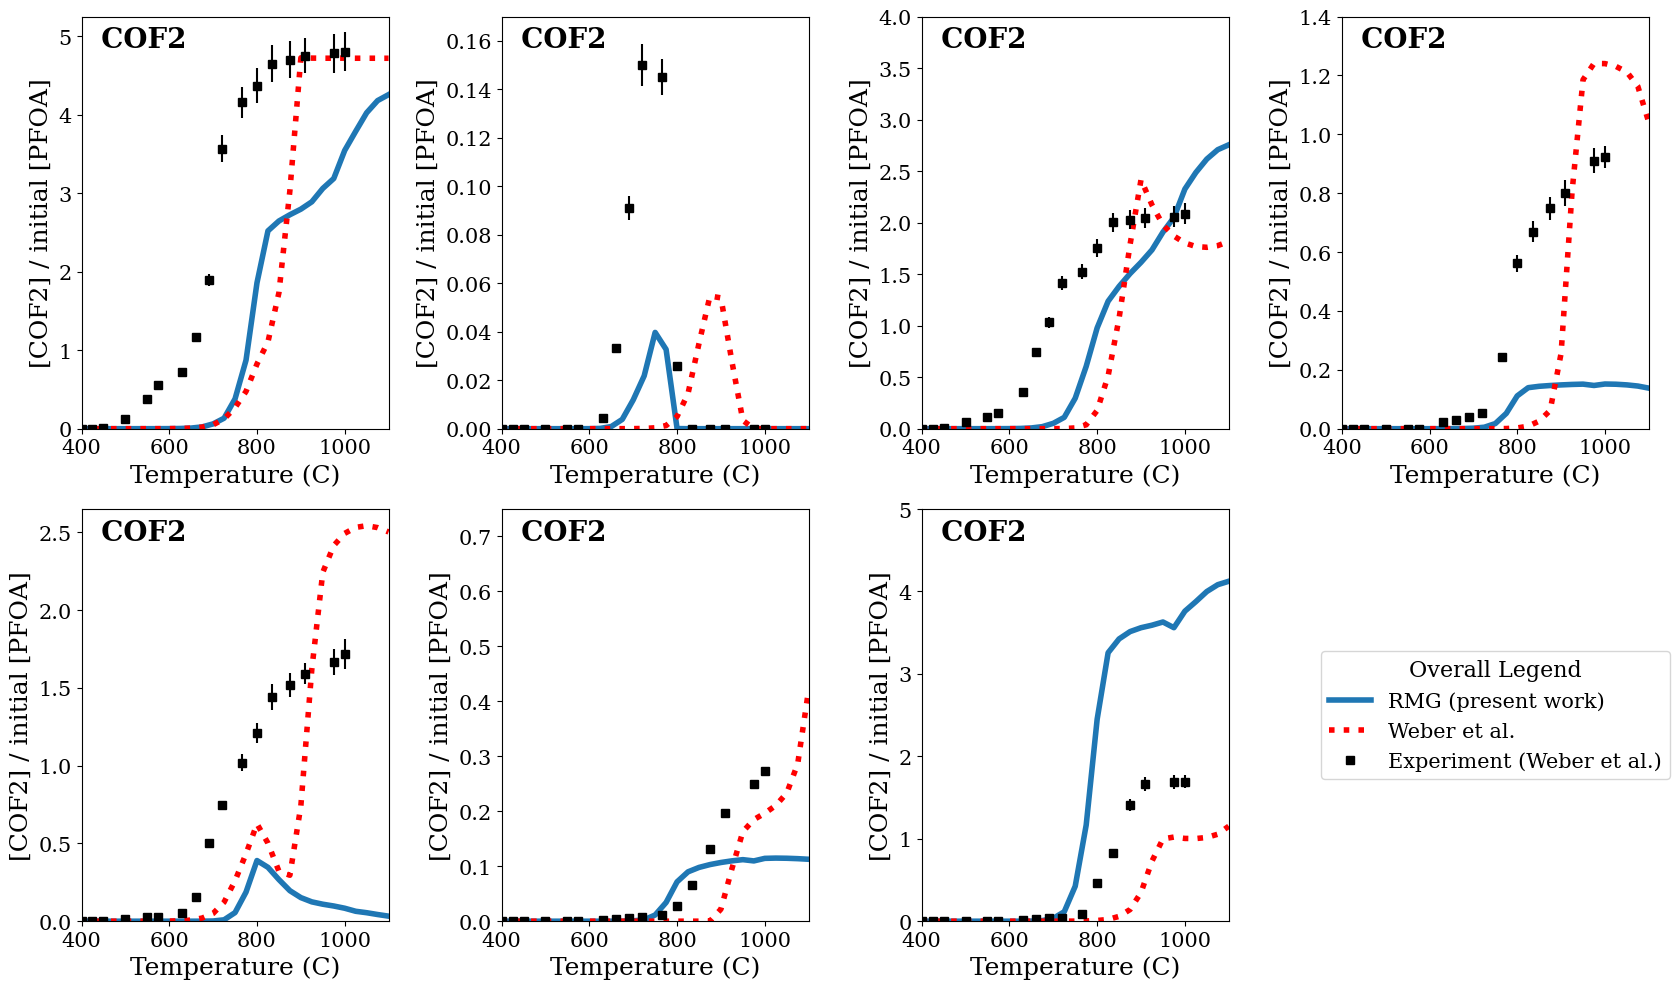

In [109]:
#switch True for all the mechanism you'd like to plot
plot_Weber = True
plot_RMG = True

#################### make sure we have the data to plot ####################################

pull_results_from_json = False #if you'd like to just pull the results from the saved json, switch this flag to True

if pull_results_from_json == True: 

    try: 
       #try loading the saved results for Weber
       with open("./weber_mechanism_results.json", 'r') as file:
           pfr_simulation_results_at_various_setpoints_weber = json.load(file)
    except (FileNotFoundError, json.JSONDecodeError):    
        print("Could not load weber_mechanism_results.json — please rerun the PFR simulation cell to generate results for plotting.")


    try: 
       #try loading the saved results for RMG
       with open("./RMG_present_work_results.json", 'r') as file:
           pfr_simulation_results_at_various_setpoints_RMG = json.load(file)
    except (FileNotFoundError, json.JSONDecodeError):    
        print("Could not load RMG_present_work_results.json — please rerun the PFR simulation cell to generate results for plotting.")



################### define some variables that we will need for plotting ##########################
axes_for_plotting = {'HF': [0,0],
                    'C2F4': [0,1],
                    'CO2': [0,2],
                    'C2F6': [0,3],
                    'CO': [1,0],
                    'CF4': [1,1],
                    'COF2': [1,2]}


if plot_Weber == False: #if we are only plotting the RMG mechanism, use this scale
    scale_limits = {'HF': [0, 5.25], 
    'C2F4': [0, 0.17], 
    'CO2': [0, 4.0], 
    'C2F6': [0, 1.0], 
    'CO': [0, 2.0], 
    'CF4': [0, 0.7], 
    'COF2': [0, 5.0], 
                  }
else: #if we are also plotting weber, use this scale 
    scale_limits = {'HF': [0, 5.25], 
    'C2F4': [0, 0.17], 
    'CO2': [0, 4.0], 
    'C2F6': [0, 1.4], 
    'CO': [0, 2.65], 
    'CF4': [0, 0.75], 
    'COF2': [0, 5.0], 
                  }


############## plot using matplotlib #######################################

fig, axs = plt.subplots(2, 4, figsize=(17, 10))

lw = 4 #linewidth for plot lines


for species_name in axes_for_plotting.keys(): 

    plotting_axis = axes_for_plotting[species_name] #get the plotting axis for the appropriate subplot


    
    # plotting RMG mechanism 
    if plot_RMG: 

        #collect the exit concentrations along all the nominal temperature set points
        exit_concentrations_along_all_temps = [
            data_dictionary[species_name] 
            for data_dictionary in pfr_simulation_results_at_various_setpoints_RMG.values()
        ]

        temps_to_plot = list(pfr_simulation_results_at_various_setpoints_RMG.keys()) 

        #plotting the RMG (present work) mechanism 
        axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations_along_all_temps, '-', linewidth = lw, color='tab:blue', label="RMG (present work)")
       

    # plotting Weber mechanism 
    if plot_Weber: 

        #collect the exit concentrations along all the nominal temperature set points
        exit_concentrations_along_all_temps = [
            data_dictionary[species_name] 
            for data_dictionary in pfr_simulation_results_at_various_setpoints_weber.values()
        ]

        temps_to_plot = list(pfr_simulation_results_at_various_setpoints_weber.keys()) 

        #plotting the RMG (present work) mechanism 
        axs[plotting_axis[0], plotting_axis[1]].plot(temps_to_plot, exit_concentrations_along_all_temps, ':', color='r', linewidth = lw, label = 'Weber et al.')
       
    



    

    ########### Weber experiments #######################
    
    #make the error bars and make sure their ordered 
    exp_data = get_experiment_data(species_name) #grabbed from original publication figure using a data digitilizer

    errors = sorted([(x, y) for x, y in zip(exp_data['error'][0], exp_data['error'][1])]) #By default, when sorting a list of tuples, sorted() will sort based on the first element of each tuple
    experiments = sorted([(x, y) for x, y in zip(exp_data['experiments'][0], exp_data['experiments'][1])])

    yerrs = []
    for (exp_x, exp_y), (raw_error_x, raw_error_y) in zip(experiments, errors):
        if raw_error_y == 1.0232558139534884:
            raw_error_y = 0.96 #modifying this last error bar on C2F6 because it looks like there was a mistake (the error bar is way too long)
        error_length = raw_error_y - exp_y
        yerrs.append(abs(error_length))

    #also grab the Weber experiment data that I directly received via emailed excel sheet
    exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet = get_experiment_data_150mLmin(species_name)
    for temp, conc_ratio, yerr in zip(exp_temps_from_excel_sheet, exp_conc_ratios_from_excel_sheet, yerrs):
        axs[plotting_axis[0], plotting_axis[1]].errorbar(temp, conc_ratio, yerr = yerr, fmt='none', c='black')
        axs[plotting_axis[0], plotting_axis[1]].plot(temp, conc_ratio, 's', c='black')  

    axs[plotting_axis[0], plotting_axis[1]].plot([],[], 's', c='black', label = 'Experiment (Weber et al.)') #required for legend handles




    axs[plotting_axis[0], plotting_axis[1]].set_xlabel('Temperature (C)')
    axs[plotting_axis[0], plotting_axis[1]].set_ylabel(f'[{web_spc}] / initial [PFOA]')
    axs[plotting_axis[0], plotting_axis[1]].set_title(f'  {web_spc}', fontsize = 20, fontweight='bold', loc='left', y=1.0, pad=-22)
    axs[plotting_axis[0], plotting_axis[1]].set_xlim(400, 1100)
    # axs[plotting_axis[0], plotting_axis[1]].set_ylim(0, 2)

    [lower_y, higher_y] = scale_limits[species_name]
    axs[plotting_axis[0], plotting_axis[1]].set_ylim(lower_y, higher_y)


#custom legend that will sit in empty plot
h, l = axs[plotting_axis[0], plotting_axis[1]].get_legend_handles_labels()


# target the empty subplot (bottom-right)
ax_legend = axs[1, 3]

# hide its axes and frame
ax_legend.axis('off')
ax_legend.set_frame_on(False)

# place the combined legend in this specific subplot
ax_legend.legend(h, l, loc='center', title="Overall Legend", fontsize=15, title_fontsize=16)

#explicitly mention the parameters for experiment
if Vdot==150: 
    fig.text(
        0.88, 0.15, f"Feed:\n402 ppm PFOA\n750 ppm H2O\n150 mL/min air", 
        fontsize=19, color="black", weight="normal",
        ha="center", va="center", 
        # bbox=dict(facecolor="white", alpha=0.8, edgecolor="gray")
    )
if Vdot==50: 
    fig.text(
        0.88, 0.15, "Feed:\n467 ppm PFOA\n750 ppm H2O\n50 mL/min air", 
        fontsize=19, color="black", weight="normal",
        ha="center", va="center", 
        # bbox=dict(facecolor="white", alpha=0.8, edgecolor="gray")
    )

plt.show()

#uncomment if you'd like to save the figure
# fig.savefig('./model_results.pdf')


# Temperature Profiles

(0.0, 60.0)

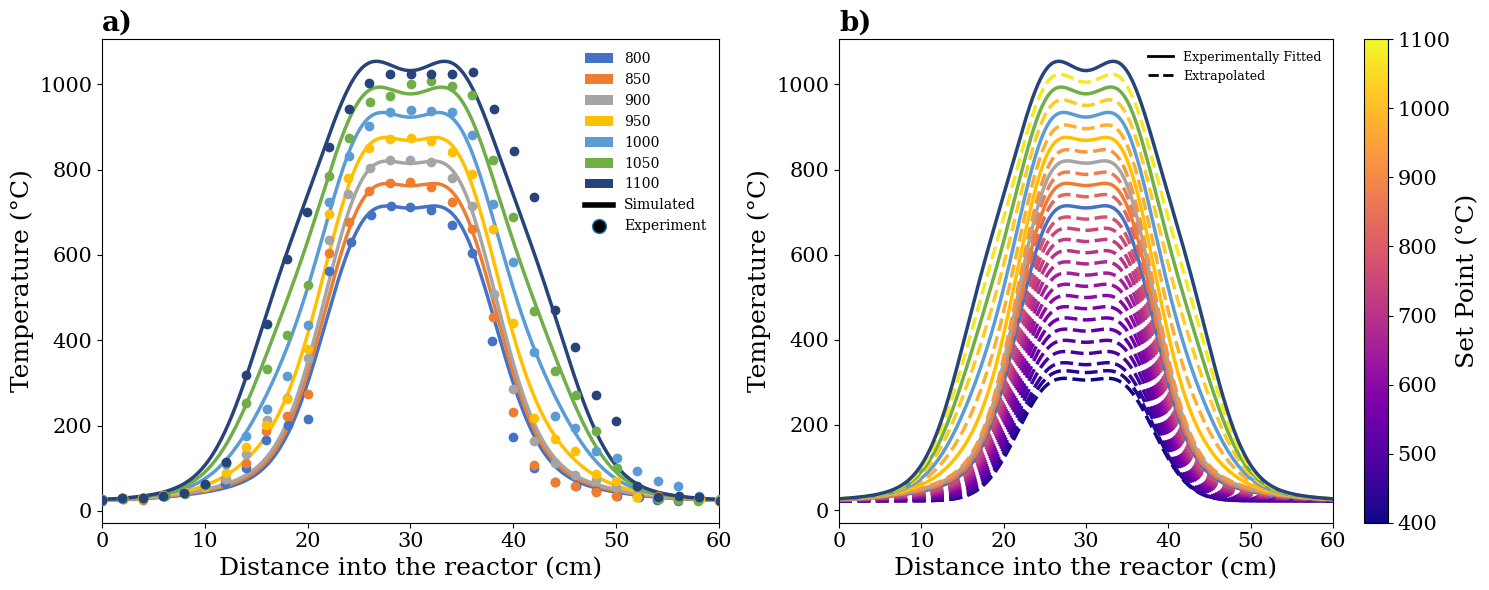

In [103]:
#  --- Temperature profiles: imposed vs simulated ---

def color_for_temperature(value, min_temp=400, max_temp=1100):
    color_map = plt.get_cmap('plasma')
    clipped_value = np.clip(value, min_temp, max_temp)
    normalized = (clipped_value - min_temp) / (max_temp - min_temp)
    return color_map(normalized)

def plot_experiment_temperature_profiles(temp): 
    temperature_profiles = pd.read_csv('./weber_experiment_data/temperature_profiles_from_literature.csv')
    index_of_x = temperature_profiles.columns.get_loc(str(temp))
    index_of_y = index_of_x+1 
    
    distances_str = temperature_profiles.iloc[:, index_of_x]
    distances = [float(x) for x in distances_str[1:]]
    
    temperatures_at_distances_str = temperature_profiles.iloc[:, index_of_y]
    temperatures_at_distances = [float(x) for x in temperatures_at_distances_str[1:]]
            
    return distances, temperatures_at_distances

rbg_colors = {800: (68, 114, 196), 
              850: (238, 125, 49), 
              900: (165, 165, 165), 
              950: (255, 192, 2), 
              1000: (91, 156, 213), 
              1050: (112, 174, 71), 
              1100: (38, 68, 121)}

#################### make sure we have the data to plot ####################################

pull_results_from_json = False #if you'd like to just pull the results from the saved json, switch this flag to True

if pull_results_from_json == True: 

    try: 
       #try loading the saved results for Weber
       with open("./weber_mechanism_results.json", 'r') as file:
           pfr_simulation_results_at_various_setpoints_weber = json.load(file)
    except (FileNotFoundError, json.JSONDecodeError):    
        print("Could not load weber_mechanism_results.json — please rerun the PFR simulation cell to generate results for plotting.")


    try: 
       #try loading the saved results for RMG
       with open("./RMG_present_work_results.json", 'r') as file:
           pfr_simulation_results_at_various_setpoints_RMG = json.load(file)
    except (FileNotFoundError, json.JSONDecodeError):    
        print("Could not load RMG_present_work_results.json — please rerun the PFR simulation cell to generate results for plotting.")
        
##################### plotting ###############################################

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 6))
length = 0.6
x_fine = np.linspace(0, length, 500)

################ left subplot (comparison of simulated versus measured temp profiles) ####################

nominal_temperatures = [800, 850, 900, 950, 1000, 1050, 1100] #higher temps for which experimental temp profiles were measure by Weber
for nominal_T_C in nominal_temperatures:

    simulated_temperature_profile = pfr_simulation_results_at_various_setpoints_RMG[nominal_T_C]['T']
    simulated_distance_along_pfr = pfr_simulation_results_at_various_setpoints_RMG[nominal_T_C]['x']

    non_plasma_color = tuple([color_num/255 for color_num in rbg_colors[nominal_T_C]])
    color=non_plasma_color
        
    ax1.plot(np.array(simulated_distance_along_pfr)*100, np.array(simulated_temperature_profile)-273.15, '-', color=color, linewidth=2.5) #alpha=0.5)


    #plot the temperature profiles from experiment
    exp_distance, exp_temps = plot_experiment_temperature_profiles(str(nominal_T_C))
    ax1.plot(exp_distance, exp_temps, 'o', color=color, zorder=10)


# make a custom label
custom_lines = []
T_names = []

for T, col in rbg_colors.items(): 
    non_plasma_color = tuple([color_num/255 for color_num in col])
    custom_lines.append(Patch(facecolor=non_plasma_color, label=T))
    T_names.append(T)

custom_lines.append(Line2D([0], [0], color='black', linestyle='-', lw=4, label='Simulated'))
custom_lines.append(Line2D([0], [0], marker='o', markerfacecolor='black', markersize=10, linestyle='', lw=4, label='Experiment'))


model_names = T_names + ['Simulated', 'Experiment']



ax1.legend(custom_lines, model_names, loc='upper right', fontsize=10, frameon=False)       
    
    
ax1.set_xlabel('Distance into the reactor (cm)')
ax1.set_ylabel('Temperature (°C)')
ax1.set_title('a)', fontsize=20, fontweight='bold', loc='left')

ax1.set_xlim(0, 60)

###################### right subplot (all simulated temperatures, high and low) ############################

nominal_temperatures = np.arange(400, 1101, 25) #increasing temperatures to larger range

T_colors_second_plot = []
T_names_second_plot = []
for nominal_T_C in nominal_temperatures:


    try:
        non_plasma_color = tuple([color_num/255 for color_num in rbg_colors[nominal_T_C]])
        color=non_plasma_color
        ls = '-'
        
    except KeyError: 
        color = color_for_temperature(nominal_T_C)
        ls = '--'
    
    simulated_temperature_profile = pfr_simulation_results_at_various_setpoints_RMG[nominal_T_C]['T']
    simulated_distance_along_pfr = pfr_simulation_results_at_various_setpoints_RMG[nominal_T_C]['x']

    ax2.plot(np.array(simulated_distance_along_pfr)*100, np.array(simulated_temperature_profile) - 273.15, ls, color=color, linewidth=2.5) #alpha=0.5)


#custom second legend
T_colors_second_plot = [Line2D([0], [0], color='black', linestyle='-', lw=2, label='Fit to experiments'),
                        Line2D([0], [0], color='black', linestyle='--', lw=2, label='Extrapolated')]
T_names_second_plot = ['Experimentally Fitted', 'Extrapolated']

ax2.legend(T_colors_second_plot, T_names_second_plot, loc='upper right', fontsize=9, frameon=False)      


# Create a ScalarMappable using the same parameters as your function
norm = mcolors.Normalize(vmin=400, vmax=1100)
sm = cm.ScalarMappable(cmap='plasma', norm=norm)
sm.set_array([])

# Add the colorbar
cbar = fig.colorbar(sm, ax=ax2)
cbar.set_label('Set Point (°C)')

    
ax2.set_xlabel('Distance into the reactor (cm)')
ax2.set_ylabel('Temperature (°C)')
ax2.set_title('b)', fontsize=20, fontweight='bold', loc='left')
ax2.set_xlim(0, 60)

#uncomment if you'd like to save .png of figure
#fig.savefig('temperature_profile_results.png')

# PFOA Concentration Along Reactor

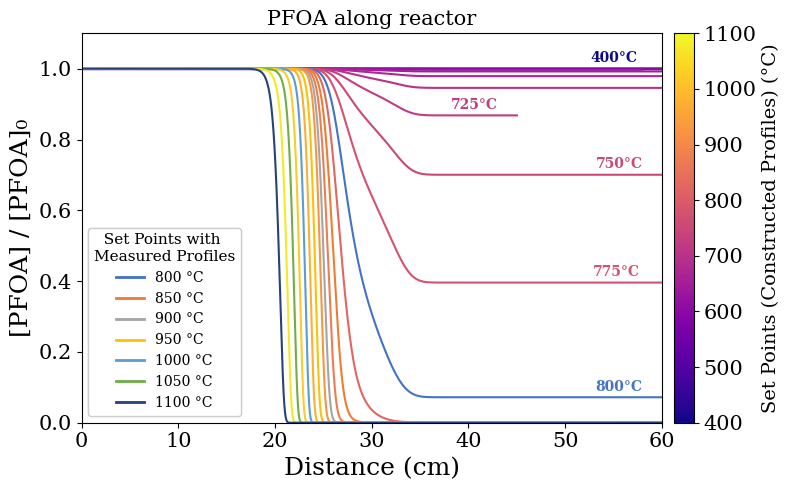

In [104]:
fig, (ax2) = plt.subplots(1, figsize=(8, 5))

#### switch depending on which mechanism you're modeling
pfr_simulation_results = pfr_simulation_results_at_various_setpoints_RMG #for RMG
#pfr_simulation_results = pfr_simulation_results_at_various_setpoints_weber #for Weber



#################### make sure we have the data to plot ####################################

pull_results_from_json = False #if you'd like to just pull the results from the saved json, switch this flag to True

if pull_results_from_json == True: 

    try: 
       #try loading the saved results for Weber
       with open("./weber_mechanism_results.json", 'r') as file:
           pfr_simulation_results_at_various_setpoints_weber = json.load(file)
    except (FileNotFoundError, json.JSONDecodeError):    
        print("Could not load weber_mechanism_results.json — please rerun the PFR simulation cell to generate results for plotting.")


    try: 
       #try loading the saved results for RMG
       with open("./RMG_present_work_results.json", 'r') as file:
           pfr_simulation_results_at_various_setpoints_RMG = json.load(file)
    except (FileNotFoundError, json.JSONDecodeError):    
        print("Could not load RMG_present_work_results.json — please rerun the PFR simulation cell to generate results for plotting.")
        
##################### plotting ###############################################

# --- PFOA destruction ---
label_these_lines = [400,725, 750, 775, 800]

for nominal_T_C in nominal_temperatures:
    if nominal_T_C not in rbg_colors.keys():
        color = color_for_temperature(nominal_T_C)
    else: 
        color = tuple([color_num/255 for color_num in rbg_colors[nominal_T_C]])


    simulated_distance_along_pfr = pfr_simulation_results[nominal_T_C]['x']



    PFOA_concentration_profile_at_this_setpoint = pfr_simulation_results[nominal_T_C]['PFOA']
    X_PFOA_0 = PFOA_concentration_profile_at_this_setpoint[0]
    
    ax2.plot(np.array(simulated_distance_along_pfr) * 100, np.array(PFOA_concentration_profile_at_this_setpoint) / X_PFOA_0, '-', color=color,
             label=f'{nominal_T_C} °C')


    # --- Add inline label for constructed-profile (plasma) set points only ---
    x_vals = np.array(simulated_distance_along_pfr) * 100
    y_vals = np.array(PFOA_concentration_profile_at_this_setpoint) / X_PFOA_0
    if nominal_T_C in label_these_lines:
        #Find x-position where curve is still within plotted x-range (<=60 cm)
        mask = x_vals <= 60
        if np.any(mask):
            # Place label near the end of the visible curve, slightly above it
            label_x = x_vals[mask][-1]
            label_y = y_vals[mask][-1]
            ax2.annotate(f'{nominal_T_C}°C',
                         xy=(label_x, label_y),
                         xytext=(label_x - 2, label_y + 0.01),
                         color=color,
                         fontsize=10,
                         fontweight='bold',
                         ha='right',
                         va='bottom')





ax2.set_xlabel('Distance (cm)')
ax2.set_ylabel('[PFOA] / [PFOA]₀')
ax2.set_title('PFOA along reactor', fontsize = 15)
#ax2.legend()
ax2.set_xlim(0, 60)
ax2.set_ylim(0, 1.1)
ax2.legend()


# --- Gradient colorbar legend (for plasma-colored temperatures) ---
plasma_temps = [T for T in nominal_temperatures if T not in rbg_colors]
if plasma_temps:
    norm = mcolors.Normalize(vmin=400, vmax=1100)
    sm = cm.ScalarMappable(cmap='plasma', norm=norm)
    sm.set_array([])
    cbar = plt.colorbar(sm, ax=ax2, pad=0.02, fraction=0.046)
    cbar.set_label('Set Points (Constructed Profiles) (°C)', fontsize=14)
    # cbar.set_ticks(plasma_temps)

# --- Second legend for RGB-defined temperatures ---
rgb_handles = [
    mlines.Line2D([], [], color=tuple(c/255 for c in rgb), linewidth=2,
                  label=f'{T} °C')
    for T, rgb in rbg_colors.items()
    if T in nominal_temperatures
]
if rgb_handles:
    legend = ax2.legend(handles=rgb_handles, title='  Set Points with \nMeasured Profiles',
        loc='lower left',
        # bbox_to_anchor=(1.4, .6),  # anchor to bottom-right outside plot
        fontsize=10,
        title_fontsize=11,
        framealpha=0.9,
        bbox_transform=fig.transFigure)
    ax2.add_artist(legend)


plt.tight_layout()
plt.show()


#uncomment to save
#fig.savefig('./PFOA_along_reactor.pdf')
